# 01 · Exploratory data analysis

Goal: understand the data before modeling. Four questions drive this notebook:

1. How rare is fraud? (It decides which metrics make sense.)
2. Which transactions are riskier: what amount, at what time, in which kind of store?
3. Is the fraud rate stable over time? (It decides how to split the data.)
4. How does fraud unfold on a single card? (It hints at which features to build later.)

The data is the [Sparkov simulated dataset](https://www.kaggle.com/datasets/kartik2112/fraud-detection): transactions generated by a simulator for 1,000 fictional cardholders, so no real person is behind any row.

In [1]:
from pathlib import Path

# Reload the project packages automatically, so code edits show up without restarting the kernel.
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Fixed colors: blue is always "legit", orange is always "fraud".
LEGIT, FRAUD = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=[LEGIT, FRAUD, "#1baf7a", "#eda100"]),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.dpi": 110,
})

In [2]:
from fraud_core.columns import TARGET, TIME
from fraud_training.data import load_raw

df = load_raw()
print(df.shape)
df.head(3).T

(1852394, 22)


,0,1,2
trans_date_trans_time,2019-01-01 00:00:18,2019-01-01 00:00:44,2019-01-01 00:00:51
cc_num,2703186189652095,630423337322,38859492057661
merchant,"fraud_Rippin, Kub and Mann","fraud_Heller, Gutmann and Zieme",fraud_Lind-Buckridge
category,misc_net,grocery_pos,entertainment
amt,4.97,107.23,220.11
first,Jennifer,Stephanie,Edward
last,Banks,Gill,Sanchez
gender,F,F,M
street,561 Perry Cove,43039 Riley Greens Suite 393,594 White Dale Suite 530
city,Moravian Falls,Orient,Malad City


Main columns:

| Column | Meaning |
|---|---|
| `trans_date_trans_time` | when the purchase happened |
| `cc_num` | card number (identifies the card) |
| `merchant`, `category` | store name and type of store |
| `amt` | purchase amount (USD) |
| `gender`, `dob`, `city_pop`, `lat`, `long` | cardholder: gender, birth date, size and location of home city |
| `merch_lat`, `merch_long` | where the store is |
| `is_fraud` | 1 = fraud, 0 = legit |

## 1. Class balance

In [3]:
counts = df[TARGET].value_counts().rename({0: "legit", 1: "fraud"})
print(counts)
print(f"\nFraud rate: {100 * df[TARGET].mean():.2f}%")
print(f"Accuracy of always predicting 'legit': {100 * (1 - df[TARGET].mean()):.2f}%")

is_fraud
legit    1842743
fraud       9651
Name: count, dtype: int64

Fraud rate: 0.52%
Accuracy of always predicting 'legit': 99.48%


About 1 in 200 transactions is fraud. A model that never flags anything is already 99.5% accurate, so accuracy tells us nothing. Models will be judged on precision, recall and PR-AUC instead (see `fraud_training.evaluate`).

## 2. Which transactions are riskier?

### Amount

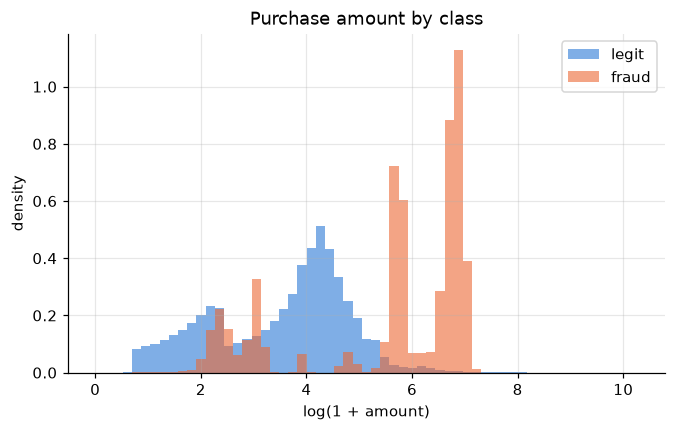

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0, np.log1p(df["amt"].max()), 60)
for label, color, name in [(0, LEGIT, "legit"), (1, FRAUD, "fraud")]:
    ax.hist(np.log1p(df.loc[df[TARGET] == label, "amt"]), bins=bins, density=True,
            alpha=0.6, color=color, label=name)
ax.set_xlabel("log(1 + amount)")
ax.set_ylabel("density")
ax.set_title("Purchase amount by class")
ax.legend()
fig.savefig(FIGURES / "eda_amount.png", bbox_inches="tight")

In [5]:
df.groupby(TARGET)["amt"].describe().rename(index={0: "legit", 1: "fraud"})

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
legit,1842743.0,67.651278,153.548108,1.00,9.610,47.24,82.560,28948.90
fraud,9651.0,530.661412,391.028873,1.06,240.075,390.00,902.365,1376.04


Frauds are much larger purchases: the median fraud is about 8 times the median legit purchase. Densities are used instead of counts, otherwise the frauds would be invisible next to 1.8 million legit rows. The amount is shown on a log scale because a few huge purchases would squash everything else; `fraud_core.features` applies the same `log1p`.

### Time of day

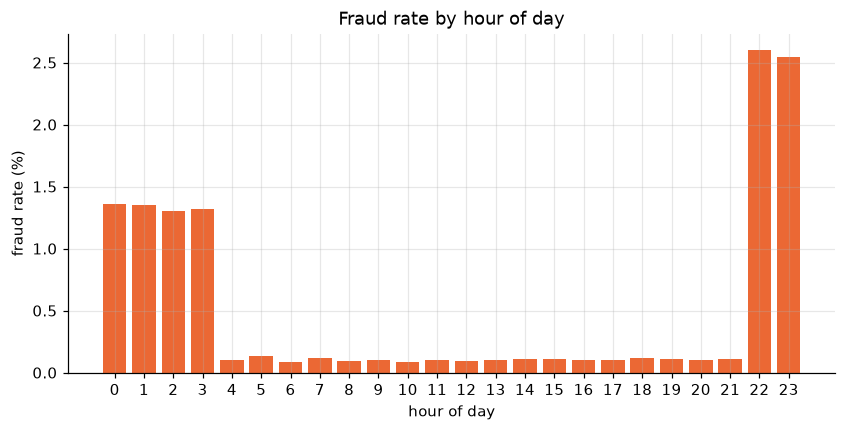

In [6]:
by_hour = df.groupby(df[TIME].dt.hour)[TARGET].mean() * 100

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_hour.index, by_hour.values, color=FRAUD)
ax.set_xticks(range(24))
ax.set_xlabel("hour of day")
ax.set_ylabel("fraud rate (%)")
ax.set_title("Fraud rate by hour of day")
fig.savefig(FIGURES / "eda_fraud_by_hour.png", bbox_inches="tight")

Fraud concentrates at night, from 22h to 3h, where the rate is 10 to 25 times higher than during the day. Note that the risky hours sit at **both ends** of the 0-23 scale. A model that reads `hour` as a plain number has to learn that 23 and 0 are neighbours, which a linear model cannot do.

### Type of store

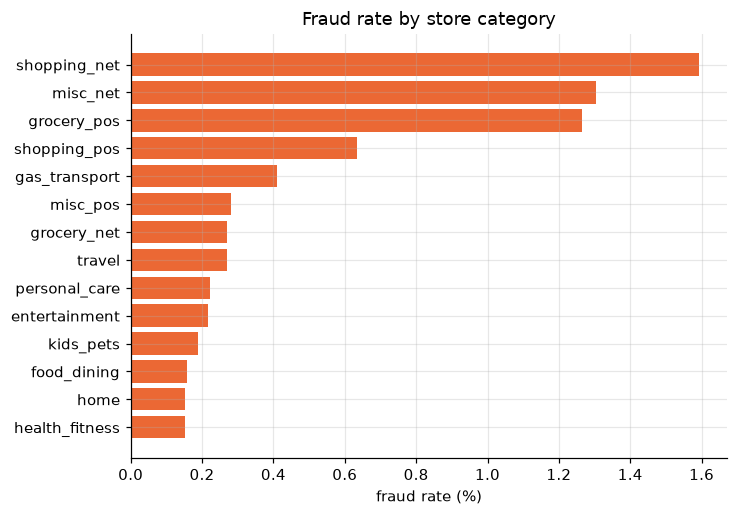

In [7]:
by_cat = df.groupby("category")[TARGET].mean().sort_values() * 100

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(by_cat.index, by_cat.values, color=FRAUD)
ax.set_xlabel("fraud rate (%)")
ax.set_title("Fraud rate by store category")
fig.savefig(FIGURES / "eda_fraud_by_category.png", bbox_inches="tight")

Online shopping (`shopping_net`, `misc_net`) and in-person groceries (`grocery_pos`) carry the highest fraud rates, roughly 10 times those of restaurants or health stores. Category is a strong feature and is one-hot encoded in `fraud_core.features`.

### Cardholder and location

In [8]:
from fraud_core.features import make_features

feats = make_features(df).assign(is_fraud=df[TARGET])
feats.groupby(TARGET)[["age", "distance_km", "log_city_pop"]].median().rename(index={0: "legit", 1: "fraud"})

,age,distance_km,log_city_pop
is_fraud,,,
legit,44.232717,78.216697,7.801391
fraud,47.808350,78.101922,7.898782


Fraud victims are slightly older on average, but the distance between home and store is the same for both classes. In this simulator stores are placed at random near the cardholder, so distance carries no signal here, even though it can matter a lot with real data.

## 3. Fraud over time

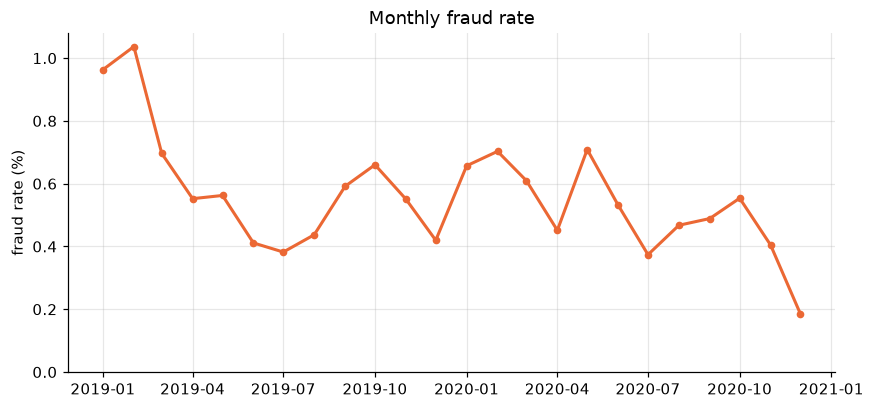

In [9]:
monthly = df.groupby(df[TIME].dt.to_period("M"))[TARGET].mean() * 100

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly.index.to_timestamp(), monthly.values, color=FRAUD, lw=2, marker="o", ms=4)
ax.set_ylim(bottom=0)
ax.set_ylabel("fraud rate (%)")
ax.set_title("Monthly fraud rate")
fig.savefig(FIGURES / "eda_fraud_over_time.png", bbox_inches="tight")

The fraud rate moves a lot from month to month, between about 0.2% and 1%. This is why the data is split by time (train on 2019, validate on the first half of 2020, test on the second half): the model has to cope with a future that does not look exactly like the past.

## 4. How fraud unfolds on a card

In [10]:
frauds = df[df[TARGET] == 1]
per_card = frauds.groupby("cc_num").agg(
    frauds=(TARGET, "size"),
    days_from_first_to_last=(TIME, lambda t: (t.max() - t.min()).total_seconds() / 86400),
)
print(f"Cards with at least one fraud: {len(per_card)} of {df['cc_num'].nunique()}")
per_card.describe().round(2)

Cards with at least one fraud: 976 of 999


,frauds,days_from_first_to_last
count,976.00,976.00
mean,9.89,1.69
std,2.98,0.38
min,2.00,0.04
25%,8.00,1.55
50%,10.00,1.89
75%,12.00,1.94
max,19.00,2.89


Fraud does not come as isolated events. Once a card is compromised, it suffers about 10 fraudulent purchases packed into roughly two days, and then it stops. A single transaction viewed alone hides this pattern, but the card's recent history would reveal it: "this card made many large night-time purchases in the last 24 hours". This is the most promising direction for feature engineering later on.

## Takeaways

- Fraud is 0.5% of the data, so accuracy is meaningless. Use precision, recall and PR-AUC.
- Fraudulent purchases are larger, happen at night (22h-3h) and concentrate in a few store categories.
- The risky hours wrap around midnight, a non-linear pattern that a linear model cannot capture from the raw hour.
- Distance between home and store carries no signal in this simulated data.
- The fraud rate drifts month to month, so we split by time.
- Frauds arrive in bursts on the same card. Features built from a card's recent history are the natural next step.